# Getting Started 

This notebook explains the basic functionality of the package, using one of the the in-built waveform models. We show how to build the waveform, create the `LISAresponse` class, and how to generate the six one arm response links. 

## 0. Imports & Parameters

In [42]:
#here are all the necessary imports 

import numpy as np
import matplotlib.pyplot as plt

from lisaorbits.file import read_orbit_file
from lisaorbits import InterpolatedOrbits

from WDM_LISAresponse.code.waveforms import waveforms

from WDM_LISAresponse.code.utils import utils

import WDM

from WDM_LISAresponse import LISAresponse

We also set-up the parameters for the example.

In [9]:
N = 2 ** 22 #number of samples
dt = 10 #seconds

theta = np.pi/3
phi = np.pi/6

Nf = 128
max_lag = 25

## 1. Orbit file 

We load the `esa-trailing-orbits.h5` file, which encodes the breathing LISA satelite orbits.

In [10]:
data = read_orbit_file('esa-trailing-orbits.h5')

times_orbits = data.t0 + data.dt * np.arange(data.size)

orbits = InterpolatedOrbits(times_orbits, data.positions, data.velocities)

lead_in = 1280.0                  # must exceed one light-travel time (~8.4 s)
t0 = times_orbits[0] + lead_in    # absolute time of the first *padded* sample

## 2. Waveform

In [48]:
times, h_plus, h_cross = waveforms.generate_windowed_waveform(
    "linear_freq", t0=t0, dt=dt, N=N,
    model_kwargs=dict(A_plus=1.0e-21, A_cross=1.0e-21,
                      f_start=2.0e-3, f_end=8.0e-3, phi_0=0.0))

#after generating the signal we pad it according to specifications

pad_info = utils.wdm_padding_info(n_samples = N,
                                  Nf = Nf,
                                  max_lag_L= max_lag)

# add a nicer way to print the padding 

for key, value in pad_info.items():
    print(key,":", value)

#we apply the padding to the waveform and data range 

times_pad, h_plus_pad, h_cross_pad = utils.apply_zero_padding(times, h_plus, h_cross, pad_info['pad_left'], pad_info['pad_right'])

input_length : 4194304
target_length : 4197888
pad_left : 1792
pad_right : 1792
rows_left : 14
rows_right : 14
guard_rows : 13
Nf : 128
Nt : 32796


## 3. Response in Time-frequency domain

We first generate the WDM class, which is responsible for the transformation.

In [30]:
wdm = WDM.WDM.WDM_transform(dt=dt, Nf=Nf, N=len(times_pad))

print(wdm)

WDM_transform(Nf=128, N=4197888, q=16, d=4, A_frac=0.25)
self.Nt = 32796 time cells
self.Nf = 128 frequency cells
self.dT = 1280.0 time resolution
self.dF = 0.000390625 frequency resolution
self.dt = 10.0 time series cadence
self.df = 2.3821502622271008e-08 time series fft frequency resolution
self.K = 4096 window length


Then, we visualise the two polarisations in the time-frequency domain.

In [31]:
wdm_h_plus = wdm(h_plus_pad)
wdm_h_cross = wdm(h_cross_pad)

We then create the LISAresponse class, which is responsible for computing the response.

In [32]:
response = LISAresponse(wdm_class=wdm, orbits_class=orbits, t0=t0, max_lag_L=max_lag, num_interp_points=16)

print(response)

We compute the response for our supplied waveform. The default calculation takes input in WDM domain and outputs six links in the WDM domain. Look at function `one_arm_response` in `response.py` if you want to vary this. 

By default, we calculate all six links, if you want to compute a subset, use the `utils.py` function `Link`.

In [33]:
wdm_one_arm_responses = response(theta=theta, phi=phi, h_plus=wdm_h_plus, h_cross=wdm_h_cross)

print(wdm_one_arm_responses.shape)

(6, 32796, 128)


By default, we calculate all six links in order: $(s,r) = [(2, 1), (3, 2),(1, 3), (3, 1), (2, 3), (1, 2)]$.  
If you want to compute a subset, use the `utils.py` function `Link`.

In [34]:
wdm_one_arm_response_12 = response.one_arm_response(theta=theta, phi=phi, h_plus=wdm_h_plus, h_cross=wdm_h_cross, 
                                                    link = utils.Link(1,2))

print(wdm_one_arm_response_12.shape)

(32796, 128)


## 4. Comparison in Time Domiain

We compute the time domain response, note that this method is slower.

In [35]:
td_one_arm_responses = response.one_arm_response_time_domain(theta = theta, phi=phi, h_plus=h_plus_pad, h_cross=h_cross_pad)

print(td_one_arm_responses.shape)

(6, 4197888)


Now we compare the two approaches together, by computing L2 error and mismatch, and by plotting.

In [ ]:
#we calculate the cut informaiton for the grids to compare signals 

cut_info = utils.wdm_cut_info(pad_info=pad_info)

td_one_arm_responses_in_wdm = wdm(td_one_arm_responses)

wdm_one_arm_responses_cut = utils.apply_wdm_cut(wdm_one_arm_responses, cut_info=cut_info)

print("The dimensions after applying a cut are:", wdm_one_arm_responses_cut.shape)

td_one_arm_responses_in_wdm_cut= utils.apply_wdm_cut(td_one_arm_responses_in_wdm, cut_info=cut_info)

for i in np.arange(6):
    res = utils.wdm_mismatch(wdm_one_arm_responses_cut[i,:,:], td_one_arm_responses_in_wdm_cut[i,:,:])
    print(response.link_convention[i])
    print(" Mismatch:", res['mismatch'])
    print(" L2 error:", res['rel_L2'])



The dimensions after applying a cut are: (6, 32768, 127)
Link(2->1)
 Mismatch: 2.497774785549142e-06
 L2 error: 2.5392092933077295e-06
Link(3->2)
 Mismatch: 1.7707170750301716e-06
 L2 error: 1.7818296120738614e-06
Link(1->3)
 Mismatch: 2.3890425898372338e-06
 L2 error: 2.403101262913213e-06
Link(3->1)
 Mismatch: 2.3864547945349336e-06
 L2 error: 2.398532589728803e-06
Link(2->3)
 Mismatch: 1.6622203757489447e-06
 L2 error: 1.6916576489572122e-06
Link(1->2)
 Mismatch: 2.5066842521034787e-06
 L2 error: 2.5245211423941485e-06


From the results above, you can see that an evolving monochromatic signal has an L2 error of $\sim 10^{-3}$ and a mismatch of $\sim 10^{-6}$, which appears due to the mixing of on-bin and off-bin realisations of the signal (for more details, see `accuracy_analysis.ipynb`).

We also plot the $2\rightarrow 1$ to show the differences between the two methods.

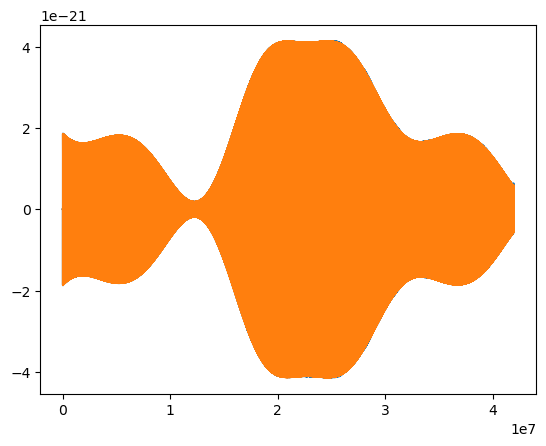

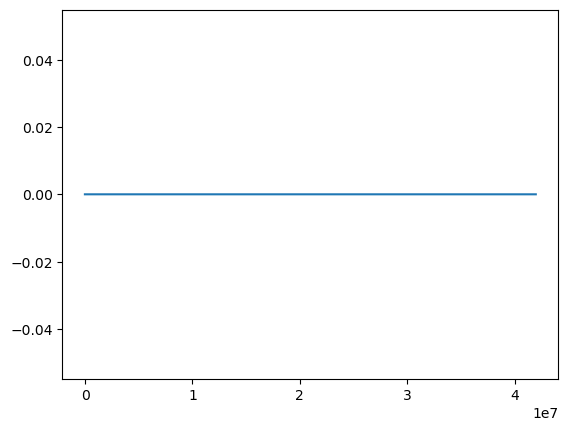

In [ ]:
wdm_one_arm_response_12_in_td = wdm.idwt(wdm_one_arm_responses[0,:])
td_one_arm_response_12 = td_one_arm_responses[0,:]

#we plot the signal for a range of 30 days starting from the centre of the data stream.

plt.plot(times_pad-t0, wdm_one_arm_response_12_in_td)
plt.plot(times_pad-t0, td_one_arm_response_12)
plt.show()

#residual of the two links

plt.plot(times_pad-t0, np.abs(td_one_arm_response_12-td_one_arm_response_12))
plt.show()

